In [ ]:
#/content/drive/MyDrive/PenambanganData_Tugas_1/student_performance_preprocessing_issues.csv

**Data Cleansing & Transformation -- Student Performance**

**Setup dan load data**

In [2]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
warnings.filterwarnings("ignore"); pd.set_option("display.max_columns", None); sns.set_style("whitegrid")

FILE = "/content/drive/MyDrive/PenambanganData_Tugas_1/student_performance_preprocessing_issues.csv"
TARGET, ID_COL = "exam_score", "student_id"
NUM = ["study_hours_per_day", "attendance_percent", "sleep_hours", "previous_score", "exam_score"]   # kolom numerik (sebagian bertipe teks)

def text_cols(d):
    return [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]

# PENTING: keep_default_na=False agar kategori valid "None" (tidak ikut bimbingan) tidak terbaca sebagai NaN
df_raw = pd.read_csv(FILE, keep_default_na=False)
df = df_raw.copy()
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (153, 13)


,student_id,gender,parental_education,lunch_type,test_preparation,internet_access,motivation_level,school_type,study_hours_per_day,attendance_percent,sleep_hours,previous_score,exam_score
0,STU001,Male,Bachelor,Standard,Completed,Yes,High,Private,5.8,84.7,6.5,67,98.0
1,STU002,Female,Bachelor,Free/Reduced,None,Yes,Low,Public,2.2,78.0,7.9,79,81.0
2,STU003,Male,High School,Standard,Completed,Yes,Medium,Public,4.8,87.4,4.2,79,99.0
3,STU004,male,Associate,Free/Reduced,None,Yes,High,Private,3.7,82.5,7.0,62,83.0
4,STU005,Male,High School,Standard,Completed,No,High,Public,1.9,94.1,5.4,80,92.0


**Ekplorasi Awal**

In [3]:
df.info()
print("\nCatatan: kolom numerik bertipe teks => ada nilai non-angka yang menyusup.")
print("Sel kosong per kolom:", (df_raw == "").sum()[(df_raw == "").sum() > 0].to_dict())
print("Baris duplikat penuh:", df.duplicated().sum(), "| ID ganda:", df[ID_COL].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   student_id           153 non-null    object 
 1   gender               153 non-null    object 
 2   parental_education   153 non-null    object 
 3   lunch_type           153 non-null    object 
 4   test_preparation     153 non-null    object 
 5   internet_access      153 non-null    object 
 6   motivation_level     153 non-null    object 
 7   school_type          153 non-null    object 
 8   study_hours_per_day  153 non-null    object 
 9   attendance_percent   153 non-null    object 
 10  sleep_hours          153 non-null    float64
 11  previous_score       153 non-null    object 
 12  exam_score           153 non-null    object 
dtypes: float64(1), object(12)
memory usage: 15.7+ KB

Catatan: kolom numerik bertipe teks => ada nilai non-angka yang menyusup.
Sel kosong per k

**deteksi kesalahan entri**

In [7]:
CAT = [c for c in text_cols(df) if c not in NUM + [ID_COL]]
for c in CAT:
    print(f"\n{c}:", {repr(k): v for k, v in df[c].value_counts().items()})


gender: {"'Female'": 81, "'Male'": 68}

parental_education: {"'Bachelor'": 54, "'High School'": 48, "'Associate'": 38, "'Master'": 9}

lunch_type: {"'Standard'": 117, "'Free/Reduced'": 36}

test_preparation: {"'None'": 92, "'Completed'": 61}

internet_access: {"'Yes'": 132, "'No'": 19}

motivation_level: {"'Medium'": 74, "'High'": 50, "'Low'": 29}

school_type: {"'Public'": 94, "'Private'": 59}


**deteksi ala groupby().count() dan opsi upper/lower/title**

In [8]:
# Deteksi ala kode asli: groupby(...).count()
display(df_raw.groupby("gender").count()[[ID_COL]].rename(columns={ID_COL: "jumlah"}))
# Tiga opsi penyeragaman huruf: .upper() / .lower() / .title()
g = df_raw["gender"].str.strip()
for nama in ["upper", "lower", "title"]:
    print(f".{nama}():", getattr(g.str, nama)().unique().tolist())

,jumlah
gender,
,3
FEMALE,1
FEMALE,1
Female,79
Male,67
N/A,1
male,1


.upper(): ['MALE', 'FEMALE', '', 'N/A']
.lower(): ['male', 'female', '', 'n/a']
.title(): ['Male', 'Female', '', 'N/A']


**solusi kesalahan entri, spasi, dan placeholder**

In [9]:
PLACEHOLDER = {"", "n/a", "na", "?", "--", "-", "unknown"}        # catatan: "none" SENGAJA tidak dimasukkan
def tidy(v):
    if not isinstance(v, str): return v
    v = re.sub(r"\s+", " ", v).strip()                            # spasi ganda -> satu, depan/belakang dibuang
    return np.nan if v.lower() in PLACEHOLDER else v
for c in text_cols(df): df[c] = df[c].map(tidy)

for c in CAT: df[c] = df[c].str.title()                           # .title() ; alternatif .upper() / .lower()
TYPO = {"Bachellor": "Bachelor", "Complete": "Completed", "Yess": "Yes", "Medum": "Medium", "Free / Reduced": "Free/Reduced"}
df[CAT] = df[CAT].replace(TYPO)

for c in CAT:
    print(f"{c}:", df[c].value_counts(dropna=False).to_dict())

gender: {'Female': 81, 'Male': 68, nan: 4}
parental_education: {'Bachelor': 54, 'High School': 48, 'Associate': 38, 'Master': 9, nan: 4}
lunch_type: {'Standard': 117, 'Free/Reduced': 36}
test_preparation: {'None': 92, 'Completed': 61}
internet_access: {'Yes': 132, 'No': 19, nan: 2}
motivation_level: {'Medium': 74, 'High': 50, 'Low': 29}
school_type: {'Public': 94, 'Private': 59}


**cek spasi berlebih**

In [10]:
sisa = {c: int((df[c].dropna() != df[c].dropna().str.strip()).sum()) for c in CAT}
print("Sisa nilai dengan spasi berlebih per kolom:", sisa)
print("Contoh kategori bernama dua kata tetap utuh:", df["parental_education"].dropna().unique().tolist())

Sisa nilai dengan spasi berlebih per kolom: {'gender': 0, 'parental_education': 0, 'lunch_type': 0, 'test_preparation': 0, 'internet_access': 0, 'motivation_level': 0, 'school_type': 0}
Contoh kategori bernama dua kata tetap utuh: ['Bachelor', 'High School', 'Associate', 'Master']


**konversi teks ke angka**

In [11]:
NUM_TEXT = {"5 hours": 5.0, "75 points": 75.0, "eighty": 80.0, "ninety": 90.0}   # manual overrule
for c in NUM:
    if not pd.api.types.is_numeric_dtype(df[c]):
        teks = df[c].dropna()[pd.to_numeric(df[c].dropna(), errors="coerce").isna()].tolist()
        df[c] = pd.to_numeric(df[c].map(lambda v: str(NUM_TEXT.get(v, v)) if pd.notna(v) else v), errors="coerce")
        print(f"{c}: nilai teks yang ditemukan -> {teks}")
df[NUM].describe().T

study_hours_per_day: nilai teks yang ditemukan -> ['5 hours']
attendance_percent: nilai teks yang ditemukan -> ['eighty']
previous_score: nilai teks yang ditemukan -> ['75 points']
exam_score: nilai teks yang ditemukan -> ['ninety']


,count,mean,std,min,25%,50%,75%,max
study_hours_per_day,148.0,4.812838,2.412024,-2.0,3.4,4.95,6.0,25.0
attendance_percent,149.0,82.277852,12.683485,-5.0,77.0,81.80,88.5,150.0
sleep_hours,153.0,6.731373,1.507938,0.0,5.9,6.80,7.4,18.0
previous_score,153.0,68.816993,13.217033,-10.0,61.0,69.00,76.0,100.0
exam_score,151.0,90.768212,8.838887,69.0,86.0,90.00,97.5,150.0


**impossible value**

In [12]:
RULES = {"study_hours_per_day": (0, 16), "attendance_percent": (0, 100), "sleep_hours": (2, 14),
         "previous_score": (0, 100), "exam_score": (0, 100)}
mask_any = pd.Series(False, index=df.index)
for c, (lo, hi) in RULES.items():
    bad = (df[c] < lo) | (df[c] > hi)
    mask_any |= bad
    print(f"{c}: batas [{lo}, {hi}] -> {int(bad.sum())} nilai tidak valid:", df.loc[bad, c].tolist())
print(f"\nSolusi (b) delete rows akan membuang {int(mask_any.sum())} baris; solusi (a) replace hanya mengosongkan sel yang salah.")
for c, (lo, hi) in RULES.items():                                  # solusi (a): replace -> NaN
    df.loc[(df[c] < lo) | (df[c] > hi), c] = np.nan

study_hours_per_day: batas [0, 16] -> 2 nilai tidak valid: [25.0, -2.0]
attendance_percent: batas [0, 100] -> 2 nilai tidak valid: [150.0, -5.0]
sleep_hours: batas [2, 14] -> 2 nilai tidak valid: [18.0, 0.0]
previous_score: batas [0, 100] -> 1 nilai tidak valid: [-10.0]
exam_score: batas [0, 100] -> 1 nilai tidak valid: [150.0]

Solusi (b) delete rows akan membuang 8 baris; solusi (a) replace hanya mengosongkan sel yang salah.


**duplikat**

In [13]:
n0 = len(df); df = df.drop_duplicates().reset_index(drop=True)
print("Duplikat dihapus:", n0 - len(df), "| ID ganda tersisa:", int(df[ID_COL].duplicated().sum()), "| ukuran:", df.shape)

Duplikat dihapus: 3 | ID ganda tersisa: 0 | ukuran: (150, 13)


**deteksi missing value**

gender                 4
parental_education     4
internet_access        2
study_hours_per_day    7
attendance_percent     6
sleep_hours            2
previous_score         1
exam_score             3

Baris yang mengandung missing value: 29 dari 150


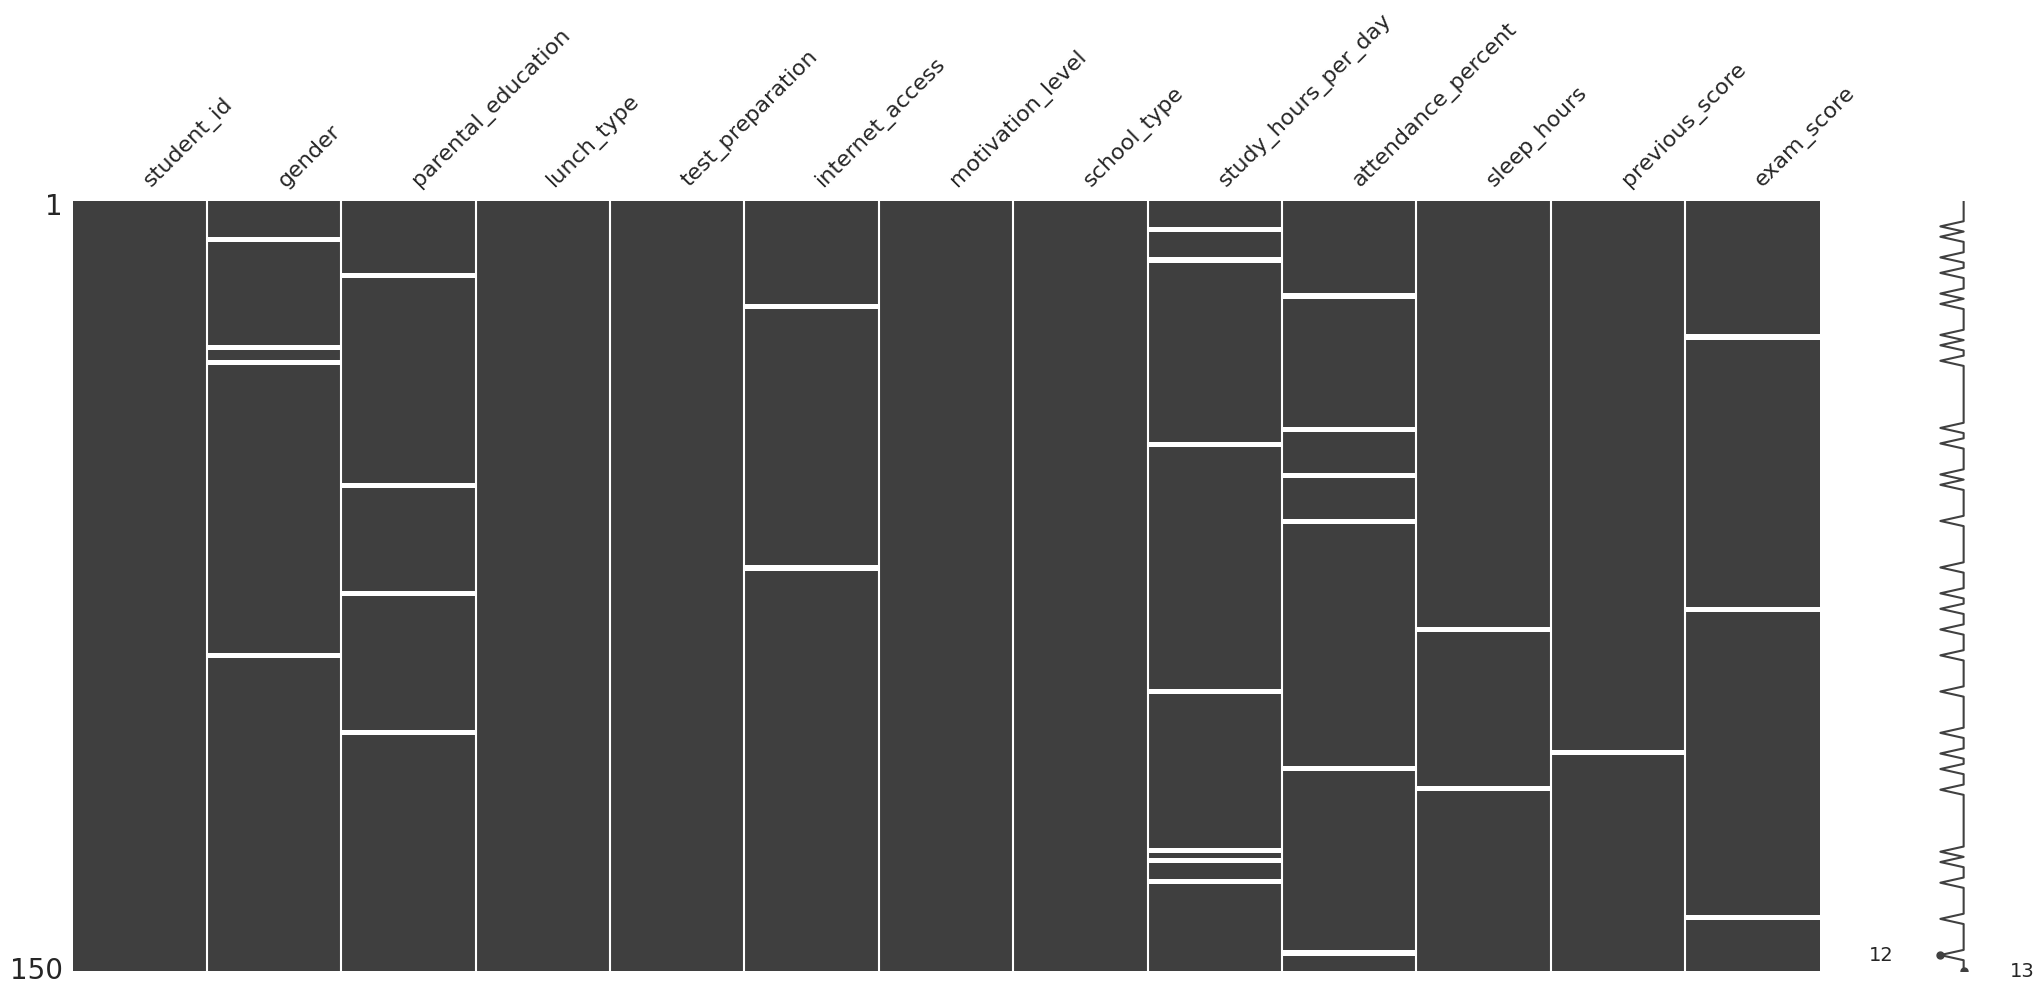

,student_id,gender,parental_education,lunch_type,test_preparation,internet_access,motivation_level,school_type,study_hours_per_day,attendance_percent,sleep_hours,previous_score,exam_score
5,STU006,Female,Bachelor,Free/Reduced,Completed,Yes,High,Public,NaN,67.6,7.1,63.0,92.0
7,STU008,NaN,Associate,Standard,None,No,Low,Public,5.2,86.1,6.6,60.0,85.0
11,STU012,Male,Bachelor,Standard,Completed,Yes,Medium,Private,NaN,83.7,5.9,55.0,89.0
14,STU015,Female,NaN,Standard,None,Yes,Low,Private,5.6,77.2,4.4,66.0,72.0
18,STU019,Female,Associate,Standard,None,Yes,Medium,Private,1.8,NaN,7.4,52.0,77.0
20,STU021,Female,Associate,Free/Reduced,None,NaN,Medium,Public,2.6,89.3,5.8,88.0,93.0
26,STU027,Female,Bachelor,Standard,None,No,Low,Private,7.0,88.5,7.1,53.0,NaN
28,STU029,NaN,Associate,Standard,None,Yes,Low,Private,4.0,93.2,6.4,82.0,90.0


In [14]:
print(df.isnull().sum()[df.isnull().sum() > 0].to_string())
rows_missing = df[df.isnull().any(axis=1)]
print(f"\nBaris yang mengandung missing value: {len(rows_missing)} dari {len(df)}")
try:
    import missingno as msno
except ImportError:                       # di Colab missingno belum terpasang
    %pip install -q missingno
    import missingno as msno
msno.matrix(df); plt.show()
rows_missing.head(8)

**set NULL dan fillna(0)**

In [15]:
# Solusi 2 (ala kode asli): set value to NULL dengan data.replace([...], np.nan) pada data mentah
df_null = df_raw.replace(["Unknown", "N/A", "?", "--", ""], np.nan)
print("Sel yang menjadi NaN per kolom:", df_null.isna().sum()[df_null.isna().sum() > 0].to_dict())
# Solusi 3 (ala kode asli): data.fillna(0) pada seluruh kolom numerik
df_fill0 = df[NUM].fillna(0); df_fill0.head()

Sel yang menjadi NaN per kolom: {'gender': 4, 'parental_education': 4, 'internet_access': 2, 'study_hours_per_day': 5, 'attendance_percent': 4, 'exam_score': 2}


,study_hours_per_day,attendance_percent,sleep_hours,previous_score,exam_score
0,5.8,84.7,6.5,67.0,98.0
1,2.2,78.0,7.9,79.0,81.0
2,4.8,87.4,4.2,79.0,99.0
3,3.7,82.5,7.0,62.0,83.0
4,1.9,94.1,5.4,80.0,92.0


**omit dan perbandingan 0, mean, median**

In [16]:
# Solusi 1: omit the value
print("dropna() baris  ->", df.dropna().shape, "(kehilangan", len(df) - len(df.dropna()), "baris)")
print("dropna(axis=1)  -> kolom tersisa:", df.dropna(axis=1).shape[1], "dari", df.shape[1], "| kolom hilang:", [c for c in df.columns if df[c].isna().any()])

# Solusi 3: impute static value (0) vs mean vs median -- demo pada study_hours_per_day
col = "study_hours_per_day"
demo = pd.DataFrame({"asli (tanpa NaN)": df[col].dropna().describe(), "isi 0": df[col].fillna(0).describe(),
                     "isi mean": df[col].fillna(df[col].mean()).describe(), "isi median": df[col].fillna(df[col].median()).describe()}).loc[["count", "mean", "std", "min"]]
demo.round(3)

dropna() baris  -> (121, 13) (kehilangan 29 baris)
dropna(axis=1)  -> kolom tersisa: 5 dari 13 | kolom hilang: ['gender', 'parental_education', 'internet_access', 'study_hours_per_day', 'attendance_percent', 'sleep_hours', 'previous_score', 'exam_score']


,asli (tanpa NaN),isi 0,isi mean,isi median
count,143.00,150.000,150.000,150.000
mean,4.74,4.519,4.740,4.752
std,1.66,1.906,1.621,1.622
min,0.50,0.000,0.500,0.500


**statistik deskriptif untuk missing value**

In [17]:
# Target yang kosong tidak diimputasi (menghindari label buatan) -> baris dibuang
print("Baris tanpa nilai target (exam_score) dibuang:", int(df[TARGET].isna().sum()))
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

num_cols = [c for c in NUM if c != TARGET]; cat_cols = CAT
stat = pd.DataFrame({"missing": df[num_cols].isna().sum(), "mean": df[num_cols].mean(), "median": df[num_cols].median(),
                     "std": df[num_cols].std(), "skewness": df[num_cols].skew()}).round(3)
stat["metode"] = np.where(stat["skewness"].abs() > 0.5, "median", "mean")
cstat = pd.DataFrame({"missing": df[cat_cols].isna().sum(), "modus": [df[c].mode().iloc[0] for c in cat_cols]})
display(stat); display(cstat[cstat["missing"] > 0])

Baris tanpa nilai target (exam_score) dibuang: 3


,missing,mean,median,std,skewness,metode
study_hours_per_day,7,4.698,4.9,1.648,-0.181,mean
attendance_percent,6,82.514,81.8,8.932,-0.033,mean
sleep_hours,2,6.694,6.8,1.069,-0.159,mean
previous_score,1,69.363,69.5,11.715,0.186,mean


,missing,modus
gender,4,Female
parental_education,4,Bachelor
internet_access,2,Yes


**imputasi**

In [19]:
for c in num_cols:
    df[c] = df[c].fillna(df[c].median() if abs(df[c].skew()) > 0.5 else df[c].mean())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode().iloc[0])
print("Sisa missing value:", int(df.isna().sum().sum()), "| ukuran:", df.shape)

Sisa missing value: 0 | ukuran: (147, 13)


**outlier (deteksi)**

,kolom,batas_bawah,batas_atas,jumlah_outlier
0,study_hours_per_day,0.15,9.35,0
1,attendance_percent,60.50,104.90,0
2,sleep_hours,3.65,9.65,0
3,previous_score,39.75,97.75,2


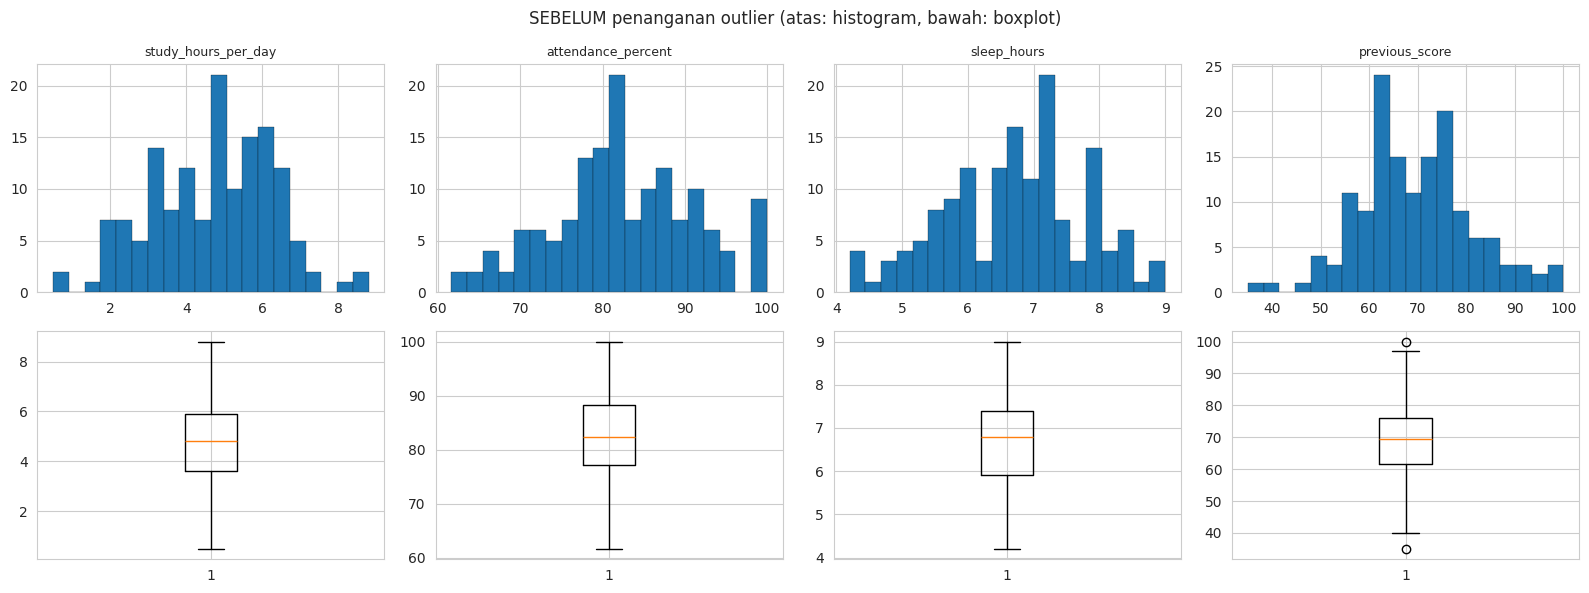

In [20]:
def bounds(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return q1 - 1.5*i, q3 + 1.5*i
tbl = pd.DataFrame([[c, *np.round(bounds(df[c]), 2), int(((df[c] < bounds(df[c])[0]) | (df[c] > bounds(df[c])[1])).sum())] for c in num_cols],
                   columns=["kolom", "batas_bawah", "batas_atas", "jumlah_outlier"]); display(tbl)
def plots(title):
    fig, ax = plt.subplots(2, len(num_cols), figsize=(4*len(num_cols), 6))
    for i, c in enumerate(num_cols):
        ax[0, i].hist(df[c], bins=20, edgecolor="black", linewidth=.2); ax[0, i].set_title(c, fontsize=9)
        ax[1, i].boxplot(df[c])
    fig.suptitle(title); plt.tight_layout(); plt.show()
plots("SEBELUM penanganan outlier (atas: histogram, bawah: boxplot)")

**outlier (penanganan) dan simpan data bersih**

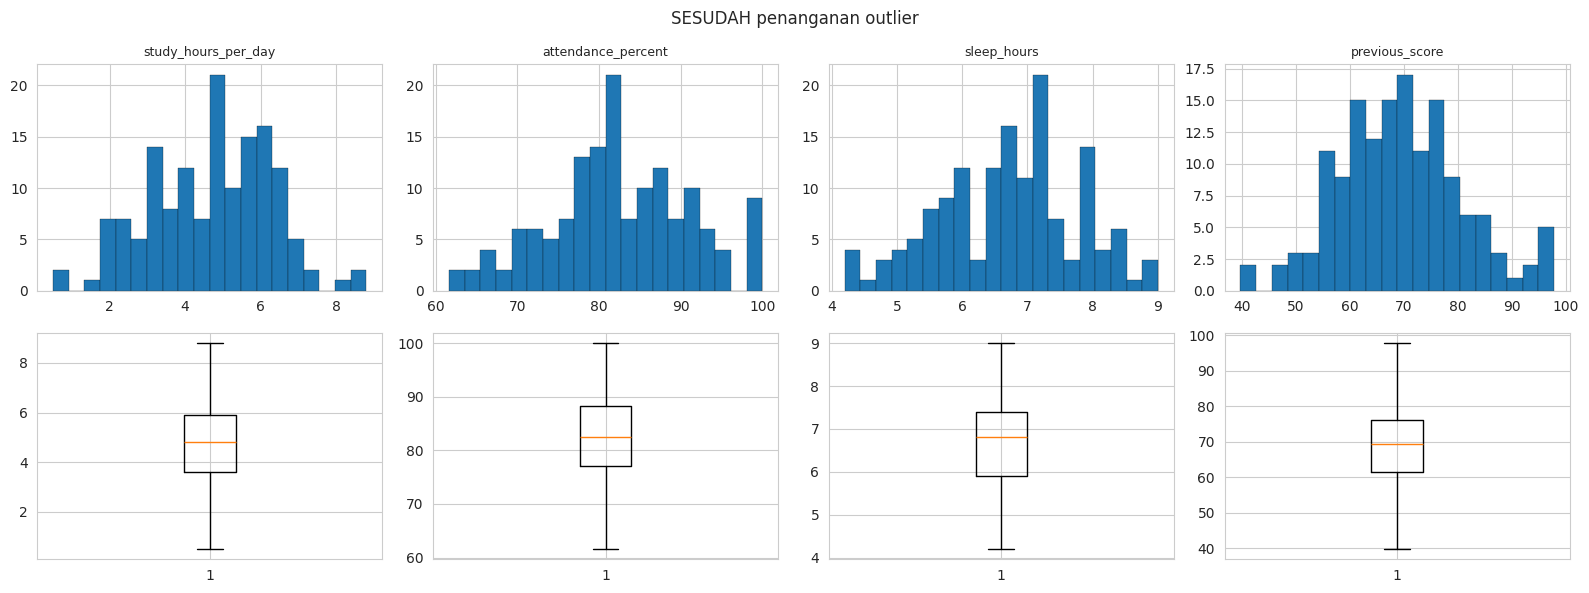

Data bersih disimpan: (147, 13)


In [21]:
for c in num_cols:
    lo, hi = bounds(df[c]); df[c] = df[c].clip(lo, hi)
plots("SESUDAH penanganan outlier")
df_clean = df.copy()
df_clean.to_csv("student_performance_clean.csv", index=False)
print("Data bersih disimpan:", df_clean.shape)

**Min-Max, Z-score, Robust (manual vs library)**

In [22]:
col = "study_hours_per_day"; x = df_clean[col]; X2 = df_clean[[col]]
q1, q3 = x.quantile(.25), x.quantile(.75)
hasil = {
 "Min-Max":  ((x - x.min()) / (x.max() - x.min()),            MinMaxScaler().fit_transform(X2).ravel()),
 "Z-score (std ddof=1, pandas)": ((x - x.mean()) / x.std(),   StandardScaler().fit_transform(X2).ravel()),
 "Z-score (std ddof=0)":         ((x - x.mean()) / x.std(ddof=0), StandardScaler().fit_transform(X2).ravel()),
 "Robust":   ((x - x.median()) / (q3 - q1),                   RobustScaler().fit_transform(X2).ravel())}
cek = pd.DataFrame({k: {"manual == library?": bool(np.allclose(m, l)), "contoh manual": round(float(m.iloc[0]), 4), "contoh library": round(float(l[0]), 4)}
                    for k, (m, l) in hasil.items()}).T
cek

,manual == library?,contoh manual,contoh library
Min-Max,True,0.6386,0.6386
"Z-score (std ddof=1, pandas)",False,0.6856,0.6879
Z-score (std ddof=0),True,0.6879,0.6879
Robust,True,0.4348,0.4348


**catatan Z-score dan Robust**

In [23]:
print("Z-score manual dibulatkan 3 desimal (seperti kode asli):", ((x - x.mean()) / x.std(ddof=0)).round(3).head(5).tolist())
print("Catatan: Z-score manual dengan .std() memakai ddof=1 sehingga berbeda tipis dari StandardScaler (ddof=0); dengan ddof=0 keduanya identik.")
print("Robust: IQR =", round(q3 - q1, 3), "(jika 0 akan terjadi pembagian nol)")

Z-score manual dibulatkan 3 desimal (seperti kode asli): [0.688, -1.559, 0.064, -0.623, -1.746]
Catatan: Z-score manual dengan .std() memakai ddof=1 sehingga berbeda tipis dari StandardScaler (ddof=0); dengan ddof=0 keduanya identik.
Robust: IQR = 2.3 (jika 0 akan terjadi pembagian nol)


**encoding dan scaling seluruh fitur**

In [24]:
ORDINAL = {"parental_education": ["High School", "Associate", "Bachelor", "Master"], "motivation_level": ["Low", "Medium", "High"]}
df_enc = df_clean.drop(columns=[ID_COL]).copy()
for c, order in ORDINAL.items(): df_enc[c] = df_enc[c].map({v: i for i, v in enumerate(order)})
nominal = [c for c in text_cols(df_enc)]
df_enc = pd.get_dummies(df_enc, columns=nominal, drop_first=True, dtype=int)
print("One-hot untuk:", nominal)

hasil_scaled = {}
for nama, sc in [("minmax", MinMaxScaler()), ("zscore", StandardScaler()), ("robust", RobustScaler())]:
    d = df_enc.copy(); d[num_cols] = sc.fit_transform(df_enc[num_cols]); hasil_scaled[nama] = d
    d.to_csv(f"student_performance_{nama}.csv", index=False)
    print(f"\n=== {nama} ==="); display(d[num_cols].describe().T[["mean", "std", "min", "max"]].round(3))

One-hot untuk: ['gender', 'lunch_type', 'test_preparation', 'internet_access', 'school_type']

=== minmax ===


,mean,std,min,max
study_hours_per_day,0.506,0.194,0.0,1.0
attendance_percent,0.545,0.228,0.0,1.0
sleep_hours,0.520,0.221,0.0,1.0
previous_score,0.511,0.199,0.0,1.0



=== zscore ===


,mean,std,min,max
study_hours_per_day,-0.0,1.003,-2.620,2.560
attendance_percent,0.0,1.003,-2.399,2.006
sleep_hours,-0.0,1.003,-2.356,2.179
previous_score,-0.0,1.003,-2.575,2.466



=== robust ===


,mean,std,min,max
study_hours_per_day,-0.044,0.699,-1.870,1.739
attendance_percent,0.010,0.788,-1.874,1.586
sleep_hours,-0.071,0.708,-1.733,1.467
previous_score,0.001,0.796,-2.042,1.958


**Ringkasan**

In [25]:
ringkas = pd.DataFrame({"Aspek": ["Baris", "Kolom", "Total missing", "Baris duplikat", "Nilai tidak valid", "Kategori tidak konsisten"],
  "Sebelum": [len(df_raw), df_raw.shape[1], int(df_raw.astype(str).apply(lambda s: s.str.strip().str.lower().isin(PLACEHOLDER)).sum().sum()), int(df_raw.duplicated().sum()), int(mask_any.sum()), "lihat bagian 1"],
  "Sesudah": [len(df_clean), df_clean.shape[1], int(df_clean.isna().sum().sum()), int(df_clean.duplicated().sum()), 0, 0]})
display(ringkas)
print({c: df_clean[c].unique().tolist() for c in CAT})

,Aspek,Sebelum,Sesudah
0,Baris,153,147
1,Kolom,13,13
2,Total missing,21,0
3,Baris duplikat,3,0
4,Nilai tidak valid,8,0
5,Kategori tidak konsisten,lihat bagian 1,0


{'gender': ['Male', 'Female'], 'parental_education': ['Bachelor', 'High School', 'Associate', 'Master'], 'lunch_type': ['Standard', 'Free/Reduced'], 'test_preparation': ['Completed', 'None'], 'internet_access': ['Yes', 'No'], 'motivation_level': ['High', 'Low', 'Medium'], 'school_type': ['Private', 'Public']}
